# Logistic Regression Model
## Loan Default Prediction

This notebook implements a Logistic Regression model to predict the probability of loan default.

The evaluation metric for this competition is **ROC-AUC**.

Based on the EDA analysis, I selected the following features:
- total_late_payments
- log_income
- log_debt_ratio

In [20]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

In [15]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (72161, 12)
Test shape: (48108, 11)


,Id,age,number_dependent_family_members,monthly_income,number_of_credit_lines,real_estate_loans,ratio_debt_payment_to_income,credit_line_utilization,number_of_previous_late_payments_up_to_59_days,number_of_previous_late_payments_up_to_89_days,number_of_previous_late_payments_90_days_or_more,defaulted_on_loan
0,1,66.0,NaN,4000.0,NaN,1.0,0.569108,0.05488766900000001,0.0,0.0,0.0,0
1,2,61.0,2.0,4000.0,6.0,1.0,0.297176,0.10194991099999999,0.0,0.0,0.0,0
2,3,31.0,2.0,3040.0,8.0,0.0,0.160145,1.22713507,4.0,0.0,0.0,1
3,4,54.0,4.0,10218.0,5.0,0.0,0.067913,0.08327777900000001,0.0,0.0,0.0,0
4,5,29.0,0.0,4468.0,6.0,0.0,0.328261,0.317445504,0.0,0.0,0.0,0


In [25]:
#at eda analysis we saw that by default some of dtype is object because instead of . we have ,
#so I need to convert now so all my numerical features are actually numerical

def convert_comma_decimal(df):
    df = df.copy()

    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].str.replace(",", ".", regex=False)
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

train = convert_comma_decimal(train)
test = convert_comma_decimal(test)

In [26]:
print(train.dtypes)
print()
print(test.dtypes)

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines                              float64
real_estate_loans                                   float64
ratio_debt_payment_to_income                        float64
credit_line_utilization                             float64
number_of_previous_late_payments_up_to_59_days      float64
number_of_previous_late_payments_up_to_89_days      float64
number_of_previous_late_payments_90_days_or_more    float64
defaulted_on_loan                                     int64
dtype: object

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines   

In [27]:
print("Remaining object columns in train:")
print(train.select_dtypes(include="object").columns.tolist())

print("\nRemaining object columns in test:")
print(test.select_dtypes(include="object").columns.tolist())

Remaining object columns in train:
[]

Remaining object columns in test:
[]


In [28]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72161 entries, 0 to 72160
Data columns (total 12 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Id                                                72161 non-null  int64  
 1   age                                               65017 non-null  float64
 2   number_dependent_family_members                   67945 non-null  float64
 3   monthly_income                                    66145 non-null  float64
 4   number_of_credit_lines                            66007 non-null  float64
 5   real_estate_loans                                 68355 non-null  float64
 6   ratio_debt_payment_to_income                      66553 non-null  float64
 7   credit_line_utilization                           65815 non-null  float64
 8   number_of_previous_late_payments_up_to_59_days    67966 non-null  float64
 9   number_of_previou

In [29]:
# Combine late payment features
train["total_late_payments"] = (
    train["number_of_previous_late_payments_up_to_59_days"] +
    train["number_of_previous_late_payments_up_to_89_days"] +
    train["number_of_previous_late_payments_90_days_or_more"]
)

test["total_late_payments"] = (
    test["number_of_previous_late_payments_up_to_59_days"] +
    test["number_of_previous_late_payments_up_to_89_days"] +
    test["number_of_previous_late_payments_90_days_or_more"]
)

train["log_income"] = np.log1p(train["monthly_income"])
test["log_income"] = np.log1p(test["monthly_income"])

train["log_debt_ratio"] = np.log1p(train["ratio_debt_payment_to_income"])
test["log_debt_ratio"] = np.log1p(test["ratio_debt_payment_to_income"])

In [30]:
#define now features and target after new implementations
TARGET = "defaulted_on_loan"
ID_COL = "Id"

features = [
    "age",
    "number_dependent_family_members",
    "number_of_credit_lines",
    "real_estate_loans",
    "credit_line_utilization",
    "total_late_payments",
    "log_income",
    "log_debt_ratio"
]

X = train[features].copy()
y = train[TARGET].copy()

X_test_final = test[features].copy()

print("Selected features:")
print(features)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

Selected features:
['age', 'number_dependent_family_members', 'number_of_credit_lines', 'real_estate_loans', 'credit_line_utilization', 'total_late_payments', 'log_income', 'log_debt_ratio']

Target distribution:
defaulted_on_loan
0    67148
1     5013
Name: count, dtype: int64

Target proportions:
defaulted_on_loan
0    0.93053
1    0.06947
Name: proportion, dtype: float64


In [31]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (57728, 8)
X_valid: (14433, 8)


In [32]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, features)
], remainder="drop")

In [33]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logreg_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse 

In [38]:
#Baseline evaluation
valid_proba = logreg_pipeline.predict_proba(X_valid)[:, 1]
valid_pred = (valid_proba >= 0.5).astype(int)

baseline_auc = roc_auc_score(y_valid, valid_proba)
baseline_acc = accuracy_score(y_valid, valid_pred)
baseline_precision = precision_score(y_valid, valid_pred, zero_division=0)
baseline_recall = recall_score(y_valid, valid_pred, zero_division=0)
baseline_f1 = f1_score(y_valid, valid_pred, zero_division=0)

print("Baseline Logistic Regression")
print("ROC-AUC:", round(baseline_auc, 4))
print("Accuracy:", round(baseline_acc, 4))
print("Precision:", round(baseline_precision, 4))
print("Recall:", round(baseline_recall, 4))
print("F1:", round(baseline_f1, 4))

Baseline Logistic Regression
ROC-AUC: 0.7736
Accuracy: 0.7551
Precision: 0.1665
Recall: 0.6301
F1: 0.2634


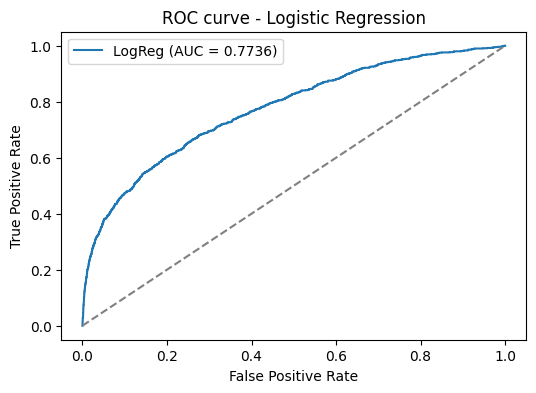

In [39]:
fpr, tpr, thresholds = roc_curve(y_valid, valid_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"LogReg (AUC = {baseline_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve - Logistic Regression")
plt.legend()
plt.show()

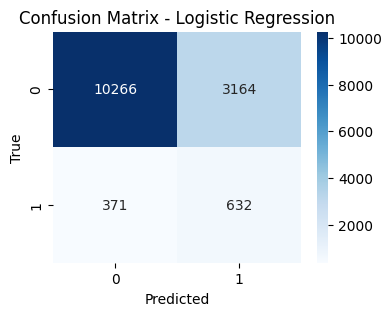

              precision    recall  f1-score   support

           0     0.9651    0.7644    0.8531     13430
           1     0.1665    0.6301    0.2634      1003

    accuracy                         0.7551     14433
   macro avg     0.5658    0.6973    0.5583     14433
weighted avg     0.9096    0.7551    0.8121     14433



In [40]:
cm = confusion_matrix(y_valid, valid_pred)

plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

print(classification_report(y_valid, valid_pred, digits=4))

The Baseline for LogReg
the ROC-AUC is 0.77 - it is quite decent baseline for Log reg, it shows that our feature engineering helped at least a little bit and model is learning real signal
Accuracy is not very informative here here because as we know our dataset is imbalanced
Precision 0.1665 = of predicted defaults just 16.6% are actually defaults, so we have quite low precision, but it can happen again because of imbalance and that log reg prioritizes recall, so it is not necessarily bad
Recall - 63% - meaning we detect 63% of actual defaults
F1 is low because we have precision being low, but in this case because we are focusing on ROC AUC that isnt that crucial.

Based on the confusion matrix if we compare missed defaulters and correctly caught one (so FN and TP) - we have model that cathes defaulters rather than minimize false alarms, which is actually good for us in this specific case (risk modeling)

In [58]:
#Hyperparameter tuning with GridSearchCV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 80.0, 100.0, 150.0, 200.0],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

grid = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__penalty': ['l2'], 'model__solver': ['lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter cand

In [61]:
print("Best CV ROC-AUC:", round(grid.best_score_, 4))
print("Best parameters:", grid.best_params_)

Best CV ROC-AUC: 0.7463
Best parameters: {'model__C': 200.0, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}


In [62]:
cv_results = pd.DataFrame(grid.cv_results_)

cols_to_show = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "param_model__C",
    "param_model__penalty",
    "param_model__solver"
]

cv_results[cols_to_show].sort_values("rank_test_score").head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,param_model__C,param_model__penalty,param_model__solver
7,1,0.746281,0.008552,0.747052,0.003149,200.00,l2,lbfgs
6,2,0.746281,0.008552,0.747052,0.003149,150.00,l2,lbfgs
5,3,0.746280,0.008552,0.747051,0.003149,100.00,l2,lbfgs
4,4,0.746280,0.008552,0.747051,0.003149,80.00,l2,lbfgs
3,5,0.746263,0.008550,0.747037,0.003149,10.00,l2,lbfgs
2,6,0.746125,0.008535,0.746899,0.003150,1.00,l2,lbfgs
1,7,0.744769,0.008378,0.745545,0.003160,0.10,l2,lbfgs
0,8,0.733570,0.007024,0.734452,0.003106,0.01,l2,lbfgs


we can see that Logistic Regression is not sensitive to C here, so values 80-250 works equally well.
Based on numbers for ROC-AUC, recall and F1 is we compare it ot baseline we have small improvement, which is expected because Logreg usually gains from tuning a little bit.

In [63]:
best_logreg = grid.best_estimator_

best_valid_proba = best_logreg.predict_proba(X_valid)[:, 1]
best_valid_pred = (best_valid_proba >= 0.5).astype(int)

best_auc = roc_auc_score(y_valid, best_valid_proba)
best_acc = accuracy_score(y_valid, best_valid_pred)
best_precision = precision_score(y_valid, best_valid_pred, zero_division=0)
best_recall = recall_score(y_valid, best_valid_pred, zero_division=0)
best_f1 = f1_score(y_valid, best_valid_pred, zero_division=0)

print("Tuned Logistic Regression")
print("ROC-AUC:", round(best_auc, 4))
print("Accuracy:", round(best_acc, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1:", round(best_f1, 4))

Tuned Logistic Regression
ROC-AUC: 0.7738
Accuracy: 0.7556
Precision: 0.167
Recall: 0.6311
F1: 0.2641


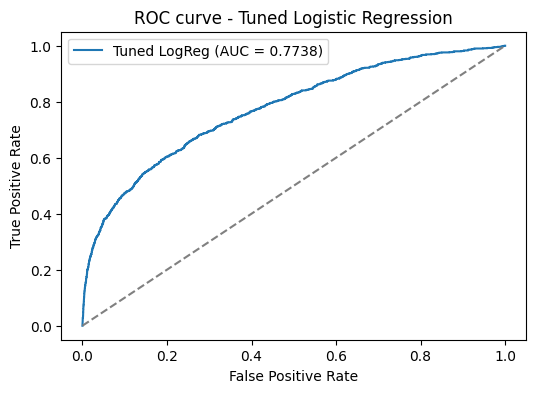

In [64]:
fpr_best, tpr_best, _ = roc_curve(y_valid, best_valid_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr_best, tpr_best, label=f"Tuned LogReg (AUC = {best_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve - Tuned Logistic Regression")
plt.legend()
plt.show()

In [65]:
#Threshold analysis
thresholds = np.linspace(0.1, 0.9, 17)

rows = []
for t in thresholds:
    pred_t = (best_valid_proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "accuracy": accuracy_score(y_valid, pred_t),
        "precision": precision_score(y_valid, pred_t, zero_division=0),
        "recall": recall_score(y_valid, pred_t, zero_division=0),
        "f1": f1_score(y_valid, pred_t, zero_division=0)
    })

threshold_df = pd.DataFrame(rows)
threshold_df

,threshold,accuracy,precision,recall,f1
0,0.10,0.069494,0.069494,1.000000,0.129956
1,0.15,0.069701,0.069508,1.000000,0.129981
2,0.20,0.078362,0.069875,0.996012,0.130588
3,0.25,0.119656,0.072540,0.990030,0.135176
4,0.30,0.199820,0.078295,0.976072,0.144962
5,0.35,0.318506,0.088128,0.942173,0.161180
6,0.40,0.479526,0.104027,0.852443,0.185426
7,0.45,0.634587,0.129832,0.746760,0.221205
8,0.50,0.755560,0.166974,0.631107,0.264080
9,0.55,0.853530,0.235854,0.494516,0.319382


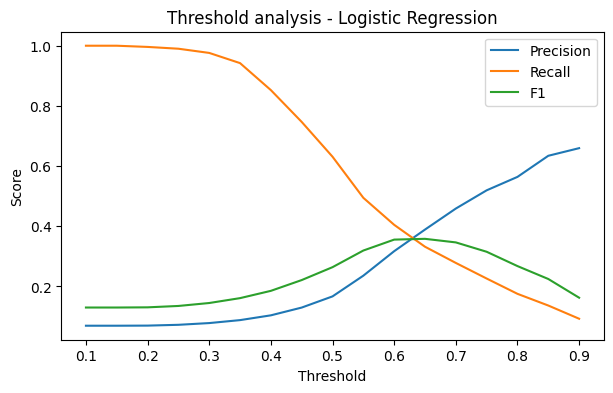

In [52]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold analysis - Logistic Regression")
plt.legend()
plt.show()

We can clearly see on the graph the trade-off between threshold and recall are really nicely can be seen:
lower threshold - more recall, higher threshold - more precision
The F1 peak is around threshold=0.62

In [53]:
coefs = best_logreg.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "feature": features,
    "coefficient": coefs,
    "abs_coefficient": np.abs(coefs)
}).sort_values("abs_coefficient", ascending=False)

coef_df

,feature,coefficient,abs_coefficient
5,total_late_payments,4.269422,4.269422
0,age,-0.374995,0.374995
6,log_income,-0.108642,0.108642
7,log_debt_ratio,-0.079193,0.079193
1,number_dependent_family_members,0.064084,0.064084
3,real_estate_loans,0.060994,0.060994
4,credit_line_utilization,-0.017306,0.017306
2,number_of_credit_lines,0.012162,0.012162


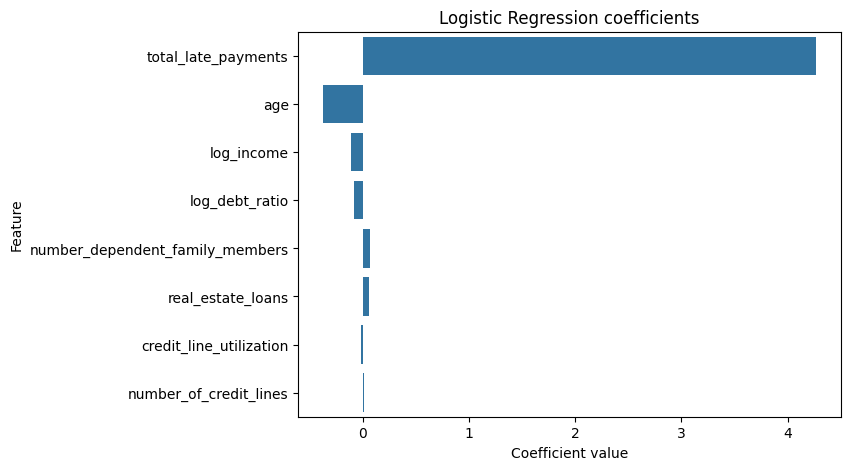

In [54]:
plt.figure(figsize=(7, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature")
plt.title("Logistic Regression coefficients")
plt.xlabel("Coefficient value")
plt.ylabel("Feature")
plt.show()

If we compare coeffs, the most important feature is total_late_payments with huge coeff 4.2, late payments are the strongest predictor of target.
Second strong is age and then our log income and dept ratio

## FINAL LOG REG
The final Logistic Regression model is trained using the optimal hyperparameters identified during GridSearchCV.
The model is fitted on the entire training dataset to maximize learning before generating probability predictions for the submission file generation.

In [66]:
# Final Logistic Regression model using best parameters from GridSearch

final_logreg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        C=200,
        penalty="l2",
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

In [67]:
# Train final model on the full dataset

final_logreg.fit(X, y) #validation split was only for evaluation, for final model we want all possible information

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse 

In [68]:
#for Kaggle we need probabilities, not labels

test_proba = final_logreg.predict_proba(X_test_final)[:, 1]

In [69]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "Predicted": test_proba
})

submission.head()

,Id,Predicted
0,1,0.560843
1,2,0.934179
2,3,0.424807
3,4,0.333942
4,5,0.674998


In [70]:
submission.to_csv("../data/logistic_regression_submission.csv", index=False)

In [71]:
print(test_proba.min(), test_proba.max())

0.0029317467361336413 1.0


Ideally we should not have 0 or 1 strict min and max... but I think we should not necessarily worried about 1 as out max (100% probability), because maybe we have output values extremely close to 1 and it was rounded to 1

In [72]:
print(test_proba.max())
print(repr(test_proba.max()))

1.0
np.float64(1.0)


well... it is just 1, the model is quite sure in this one :)
it is a little bit unusual for log reg, normally it is very close to 1 but rarely exactly 1

In [73]:
np.sum(test_proba == 1.0)

np.int64(38)

In [74]:
np.sum(test_proba > 0.999)

np.int64(39)

In [75]:
test.loc[test_proba == 1.0]

,Id,age,number_dependent_family_members,monthly_income,number_of_credit_lines,real_estate_loans,ratio_debt_payment_to_income,credit_line_utilization,number_of_previous_late_payments_up_to_59_days,number_of_previous_late_payments_up_to_89_days,number_of_previous_late_payments_90_days_or_more,total_late_payments,log_income,log_debt_ratio
594,595,NaN,0.0,600.0,NaN,0.0,0.000000,NaN,98.0,98.0,98.0,294.0,6.398595,0.000000
1478,1479,28.0,1.0,NaN,0.0,0.0,0.019300,1.0,98.0,98.0,98.0,294.0,NaN,0.019116
1944,1945,24.0,0.0,1041.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,6.948897,0.000000
3382,3383,27.0,3.0,2000.0,0.0,0.0,0.018491,1.0,98.0,98.0,98.0,294.0,7.601402,0.018322
5460,5461,52.0,2.0,9016.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,9.106867,0.000000
7380,7381,34.0,2.0,NaN,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,NaN,0.000000
9874,9875,49.0,1.0,2083.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,7.642044,0.000000
11939,11940,26.0,0.0,2000.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,7.601402,0.000000
12848,12849,21.0,0.0,0.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,0.000000,0.000000
14296,14297,27.0,0.0,3000.0,0.0,0.0,0.000000,1.0,98.0,98.0,98.0,294.0,8.006701,0.000000


Additional checking shows that yes, we have quite some 100% probabilities but after checking we see that this is probably was happening because of huge coeff for total late payments and these people missed a lot of payments, so madel became extremely confident with probabilities.

In [78]:
#submission.head()
#submission["Predicted"].between(0,1).all()